# Draft Tool: 9-Category Rankings

Ranks players by **z-scores**: how far above or below an average draftable player they are in each category, summed into a `TOTAL` value.
FG% and FT% are weighted by attempts, so a 90% FT shooter on 8 attempts counts more than one on 1 attempt. Turnovers count against a player.

**How to use it during the draft**
1. Run everything once (Run All).
2. Each time someone picks, add the name to `TAKEN` (other teams) or `MINE` (you) in the **Draft board** cell, then re-run from that cell down.
3. Names don't need accents or exact spelling: last names (`"doncic"`), initials (`"sga"`) and small typos all work if they point to only one player.

Rankings are **injury-adjusted** (`ADJ_TOTAL`) using games missed over the last 2 seasons; see the Injury risk section.

Category stats are a **blend of last season's per-game averages: 70% last 3 months (base) + 30% last month (recent form)**
(`BASE_MONTHS` / `RECENT_MONTHS` / `RECENT_WEIGHT` in Settings). The last 3 months include the last month, so it counts a bit more than 30% overall.
Players with under `MIN_GAMES` in the last 3 months use full-season stats as their base; players with under `RECENT_MIN_GAMES` in the last month
skip the recent part. Rookies and players who missed the season aren't included, so judge those yourself.

## Settings

In [1]:
SEASON = "2025-26"      # stats season the rankings are based on
NUM_TEAMS = 14
ROSTER_SLOTS = {"G": 3, "F": 3, "C": 1, "UTIL": 3}   # your lineup; UTIL takes any position. Add "BN": 3 for bench spots
ROSTER_SIZE = sum(ROSTER_SLOTS.values())             # players per team; also sets the draftable pool
BASE_MONTHS = 3          # "consistency" window: last N months of SEASON (None = full season)
RECENT_MONTHS = 1        # "recent form" window: last N months of SEASON
RECENT_WEIGHT = 0.3      # category stats = 70% base window + 30% recent window (0 = base only)
MIN_GAMES = 10           # hide players under this many games in SEASON; also the minimum for the base window
RECENT_MIN_GAMES = 6     # games needed in the recent window for recent form to count (max ~18 in a month)

CATS = ["FG_PCT", "FT_PCT", "FG3M", "PTS", "REB", "AST", "STL", "BLK", "TOV"]
PUNT = []                # categories to ignore, e.g. ["FT_PCT", "TOV"]

# Injury risk (see the "Injury risk" section)
INJURY_WEIGHT = 1.0      # 0 = ignore games-missed history, 1 = full adjustment, 0.5 = halfway
ADJUST = {               # manual availability overrides (share of games expected, 0-1) for news history can't know
    # "Joel Embiid": 0.6,
}

# Position scarcity (see best_available): if fewer than SCARCITY_MIN players eligible at a position are among
# the next SCARCITY_WINDOW available, players at that position get +SCARCITY_BOOST added to their SCORE
SCARCITY_WINDOW = 30
SCARCITY_MIN = {"G": 9, "F": 9, "C": 5}   # a typical 30-player stretch has ~14 G, ~15 F, ~8 C
SCARCITY_BOOST = 0.5                      # in SCORE units; roughly moves a player up a few spots mid-draft

## Load data (cached in `data/`)

In [2]:
import difflib
import json
import time
import unicodedata
from pathlib import Path

import pandas as pd
from nba_api.stats.endpoints import leaguedashplayerstats, leaguegamelog, playerindex

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)


def cached(name, fetch, refresh=False):
    path = DATA / name
    if path.exists() and not refresh:
        return pd.read_csv(path)
    df = fetch()
    df.to_csv(path, index=False)
    time.sleep(0.6)  # be polite to NBA.com
    return df


stats_full = cached(f"player_stats_{SEASON}.csv", lambda: leaguedashplayerstats.LeagueDashPlayerStats(
    season=SEASON, per_mode_detailed="PerGame", timeout=60).get_data_frames()[0])
season_dates = cached(f"season_dates_{SEASON}.csv", lambda: leaguegamelog.LeagueGameLog(
    season=SEASON, timeout=60).get_data_frames()[0]["GAME_DATE"].agg(["min", "max"]).to_frame().T)
date_to = pd.Timestamp(season_dates["max"].iloc[0])  # last regular-season game day


def window(months):
    """Per-game stats for the last `months` months of the regular season (None = full season), plus a label."""
    if not months:
        return stats_full.copy(), f"full {SEASON} season"
    start = date_to - pd.DateOffset(months=months)
    df = cached(f"player_stats_{SEASON}_last{months}m.csv", lambda: leaguedashplayerstats.LeagueDashPlayerStats(
        season=SEASON, per_mode_detailed="PerGame", date_from_nullable=start.strftime("%m/%d/%Y"),
        date_to_nullable=date_to.strftime("%m/%d/%Y"), timeout=60).get_data_frames()[0])
    return df, f"last {months} month{'s' if months > 1 else ''} ({start:%b %d} - {date_to:%b %d, %Y})"


BLEND = ["MIN", "PTS", "REB", "AST", "STL", "BLK", "FG3M", "TOV", "FGM", "FGA", "FTM", "FTA"]
full_gp = stats_full.set_index("PLAYER_ID")["GP"]

# Base ("consistency") window. Players with too few games in it fall back to their full-season stats.
base, base_label = window(BASE_MONTHS)
base = base[base["GP"] >= MIN_GAMES]
stats_base = pd.concat([base, stats_full[~stats_full["PLAYER_ID"].isin(base["PLAYER_ID"])]], ignore_index=True)
stats_base["GP_BASE"] = stats_base["PLAYER_ID"].map(base.set_index("PLAYER_ID")["GP"]).fillna(0).astype(int)
stats_base["GP"] = stats_base["PLAYER_ID"].map(full_gp)  # GP column always = full-season games
fallbacks = len(stats_base) - len(base)
stats = stats_base.copy()
stats_recent = None  # kept for the RANK_RECENT comparison column

if RECENT_WEIGHT:
    # Blend per-game volumes; percentages are recomputed from blended makes / attempts.
    # Players with fewer than RECENT_MIN_GAMES in the recent window keep their base numbers.
    recent, recent_label = window(RECENT_MONTHS)
    stats_recent = recent[recent["GP"] >= RECENT_MIN_GAMES].copy()
    stats = stats.merge(stats_recent[["PLAYER_ID", "GP", *BLEND]], on="PLAYER_ID", how="left", suffixes=("", "_R"))
    w = stats["GP_R"].notna() * RECENT_WEIGHT
    for c in BLEND:
        stats[c] = (1 - w) * stats[c] + w * stats[f"{c}_R"].fillna(0)
    for pct, (made, att) in {"FG_PCT": ("FGM", "FGA"), "FT_PCT": ("FTM", "FTA")}.items():
        stats[pct] = (stats[made] / stats[att].where(stats[att] > 0)).fillna(0)
    stats["GP_RECENT"] = stats["GP_R"].fillna(0).astype(int)
    no_recent = int(stats["GP_R"].isna().sum())
    stats = stats.drop(columns=[c for c in stats if c.endswith("_R")])
    print(f"Category stats: {1 - RECENT_WEIGHT:.0%} {base_label} + {RECENT_WEIGHT:.0%} {recent_label}")
    print(f"  {no_recent} players with under {RECENT_MIN_GAMES} games in the recent window use the base window only")
else:
    print(f"Category stats: {base_label}")
if BASE_MONTHS:
    print(f"  {fallbacks} players with under {MIN_GAMES} games in the base window use full-season stats instead")

index = cached(f"player_index_{SEASON}.csv", lambda: playerindex.PlayerIndex(
    season=SEASON, timeout=60).get_data_frames()[0])

# Position and current team come from the player index (reflects offseason moves)
info = index[["PERSON_ID", "POSITION", "TEAM_ABBREVIATION"]].rename(
    columns={"PERSON_ID": "PLAYER_ID", "TEAM_ABBREVIATION": "TEAM"})
players = stats.merge(info, on="PLAYER_ID", how="left")
players["TEAM"] = players["TEAM"].fillna(players["TEAM_ABBREVIATION"])
players = players[players["GP"] >= MIN_GAMES].reset_index(drop=True)
print(f"{len(players)} players with {MIN_GAMES}+ games in {SEASON}")

Category stats: 70% last 3 months (Jan 12 - Apr 12, 2026) + 30% last 1 month (Mar 12 - Apr 12, 2026)
  174 players with under 6 games in the recent window use the base window only
  118 players with under 10 games in the base window use full-season stats instead
506 players with 10+ games in 2025-26


## Z-score rankings

The average and spread for each category come from the **draftable pool** (`NUM_TEAMS × ROSTER_SIZE` best players), not from every player in the league.
Otherwise deep-bench players would drag the averages down and inflate everyone's scores.

In [3]:
PCT_CATS = {"FG_PCT": ("FGM", "FGA"), "FT_PCT": ("FTM", "FTA")}
ACTIVE = [c for c in CATS if c not in PUNT]


def zscores(df, pool_size):
    pool = df.nlargest(pool_size, "MIN")  # first guess at the pool, refined below
    for _ in range(3):
        z = pd.DataFrame(index=df.index)
        for c in CATS:
            if c in PCT_CATS:
                made, att = PCT_CATS[c]
                league_pct = pool[made].sum() / pool[att].sum()
                impact = (df[c] - league_pct) * df[att]
                pool_impact = impact.loc[pool.index]
                z[c] = (impact - pool_impact.mean()) / pool_impact.std()
            else:
                z[c] = (df[c] - pool[c].mean()) / pool[c].std()
        z["TOV"] = -z["TOV"]  # fewer turnovers is better
        z["TOTAL"] = z[ACTIVE].sum(axis=1)
        pool = df.loc[z["TOTAL"].nlargest(pool_size).index]
    return z


z = zscores(players, NUM_TEAMS * ROSTER_SIZE)
info_cols = ["PLAYER_NAME", "TEAM", "POSITION", "AGE", "GP", *[c for c in ["GP_BASE", "GP_RECENT"] if c in players], "MIN"]
rankings = pd.concat([players[info_cols], z.round(2)], axis=1)
rankings = rankings.sort_values("TOTAL", ascending=False).reset_index(drop=True)
rankings.index += 1
rankings.index.name = "RANK"


def show(df):
    """Color z-scores: green = helps you, red = hurts you."""
    fmt = {c: "{:.2f}" for c in [*CATS, "TOTAL", "ADJ_TOTAL", "BOOST", "SCORE"] if c in df}
    fmt.update({"MIN": "{:.1f}", "AGE": "{:.0f}"})
    fmt.update({c: "{:.0f}" for c in ["RANK_FULL", "RANK_RECENT"] if c in df})
    if "AVAIL" in df:
        fmt["AVAIL"] = "{:.0%}"
    score = next(c for c in ["SCORE", "ADJ_TOTAL", "TOTAL"] if c in df)
    return (df.style.format(fmt, na_rep="-")
              .background_gradient(cmap="RdYlGn", vmin=-2, vmax=2, subset=CATS)
              .background_gradient(cmap="Greens", subset=[score]))

## Name matching

Lets you type players loosely everywhere below: last names (`"doncic"`), initials (`"sga"`), nicknames (`"wemby"`) and small typos.

In [4]:
def norm(name):
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode().replace("-", " ")
    return "".join(ch for ch in name.lower() if ch.isalnum() or ch == " ").strip()


NAMES = {norm(n): n for n in rankings["PLAYER_NAME"]}

# Nicknames -> full names; add your own
ALIASES = {
    "wemby": "Victor Wembanyama", "kat": "Karl-Anthony Towns", "ad": "Anthony Davis",
    "greek freak": "Giannis Antetokounmpo", "chef curry": "Stephen Curry", "joker": "Nikola Jokic",
    "jjj": "Jaren Jackson Jr.", "cp3": "Chris Paul", "pg13": "Paul George", "dame": "Damian Lillard",
}


def resolve(name):
    """Match a typed name to a player: exact, initials, partial, then closest spelling."""
    key = norm(name)
    key = norm(ALIASES.get(key, key))
    if key in NAMES:
        return NAMES[key]
    initials = [full for k, full in NAMES.items() if "".join(w[0] for w in k.split()) == key]
    if len(initials) == 1:
        return initials[0]
    partial = [full for k, full in NAMES.items() if key in k]
    if len(partial) == 1:
        return partial[0]
    if len(partial) > 1:
        print(f"  '{name}' is ambiguous: {partial[:6]}. Type more of the name.")
        return None
    close = difflib.get_close_matches(key, NAMES, n=1, cutoff=0.75)
    if close:
        return NAMES[close[0]]
    print(f"  '{name}' not in rankings (rookie, or under {MIN_GAMES} games last season). Skipped.")
    return None

## Injury risk

Missed games cost you stats, so each player's value is discounted by how often that player has been available.

1. **Availability** = games played / 82 over the last 2 full seasons, weighted 70/30 toward the most recent
   (whole seasons, not just the stats window used for the categories).
   Seasons after a player's debut with no games (a missed year) count as 0.
2. It's **pulled toward the league average** for players with little history, so one healthy rookie year doesn't look like an iron man.
3. **`ADJ_TOTAL`** assumes that when a player sits, you start a replacement-level player (the last draftable player's value) instead:
   `ADJ_TOTAL = AVAIL x TOTAL + (1 - AVAIL) x replacement`, blended with the raw `TOTAL` by `INJURY_WEIGHT`.
   An elite player who misses games is still valuable; a middling one who misses games is close to waiver-wire level.
4. `ADJUST` in Settings overrides availability for news the history can't know (offseason surgery, suspensions).

**`RANK_FULL` / `RANK_RECENT`** show where each player would rank on the base window only (last 3 months) or the recent
window only (last month), with the same z-scores and injury adjustment, so you can see who the blend is moving and why.
`-` = too few games in the last month. `GP` = full-season games, `GP_BASE` / `GP_RECENT` = games in each window.

Caveat: games missed for non-injury reasons (out of the rotation, two-way contract) also lower availability.
The first run downloads each draftable player's history (about 5 minutes); later runs use the cache in `data/`.

In [5]:
from nba_api.stats.endpoints import playercareerstats

SEASON_WEIGHTS = [0.7, 0.3]       # most recent season first (last 2 seasons)
start = int(SEASON[:4])
HIST_SEASONS = [f"{y}-{str(y + 1)[2:]}" for y in range(start, start - len(SEASON_WEIGHTS), -1)]
SHRINK = 1.0                       # seasons' worth of league-average availability blended in
CAREER_FILE = DATA / "career_gp.csv"


def career_games(player_ids):
    """Games played per season for each player, fetched once and cached (only missing players are fetched)."""
    have = pd.read_csv(CAREER_FILE) if CAREER_FILE.exists() else pd.DataFrame(columns=["PLAYER_ID", "SEASON_ID", "GP"])
    todo = [p for p in player_ids if p not in set(have["PLAYER_ID"])]
    if todo:
        print(f"Downloading games-played history for {len(todo)} players (about {len(todo) * 1.3 / 60:.0f} min)...")
    rows = []
    for i, pid in enumerate(todo, 1):
        for attempt in range(3):
            try:
                df = playercareerstats.PlayerCareerStats(player_id=pid, timeout=60).get_data_frames()[0]
                break
            except Exception:
                time.sleep(3)
        else:
            print(f"  gave up on player {pid}")
            continue
        # Traded players have a row per team plus a 'TOT' row; max GP per season is the full-season total
        gp = df.groupby("SEASON_ID", as_index=False)["GP"].max()
        gp["PLAYER_ID"] = pid
        rows.append(gp[["PLAYER_ID", "SEASON_ID", "GP"]])
        time.sleep(0.6)
        if i % 25 == 0 or i == len(todo):
            have = pd.concat([have, *rows], ignore_index=True)
            rows = []
            have.to_csv(CAREER_FILE, index=False)
            print(f"  {i}/{len(todo)}")
    return have[have["PLAYER_ID"].isin(player_ids)]


def availability(gp_hist):
    raw = {}
    for pid, g in gp_hist.groupby("PLAYER_ID"):
        by_season = dict(zip(g["SEASON_ID"], g["GP"]))
        debut = g["SEASON_ID"].min()
        seasons = [(s, w) for s, w in zip(HIST_SEASONS, SEASON_WEIGHTS) if s >= debut]
        if seasons:
            total_w = sum(w for _, w in seasons)
            rate = sum(w * min(by_season.get(s, 0), 82) / 82 for s, w in seasons) / total_w
            raw[pid] = (rate, len(seasons))
    league_avg = pd.Series([r for r, _ in raw.values()]).mean()
    shrunk = {pid: (n * r + SHRINK * league_avg) / (n + SHRINK) for pid, (r, n) in raw.items()}
    return shrunk, league_avg


# Only the draftable range (plus a margin) matters; everyone else gets the league average
POOL = NUM_TEAMS * ROSTER_SIZE
top_names = rankings["PLAYER_NAME"].head(POOL + 75)
top_ids = players.loc[players["PLAYER_NAME"].isin(top_names), "PLAYER_ID"].tolist()
avail, league_avg = availability(career_games(top_ids))

id_by_name = dict(zip(players["PLAYER_NAME"], players["PLAYER_ID"]))
rankings["AVAIL"] = rankings["PLAYER_NAME"].map(lambda n: avail.get(id_by_name[n], league_avg)).round(2)
for name, value in ADJUST.items():
    player = resolve(name)
    if player:
        rankings.loc[rankings["PLAYER_NAME"] == player, "AVAIL"] = value
        print(f"  override: {player} availability = {value:.0%}")

# Risk relative to the draftable pool: bottom quarter = high, top quarter = low
q_low, q_high = rankings.nlargest(POOL, "TOTAL")["AVAIL"].quantile([0.25, 0.75])
rankings["RISK"] = pd.cut(rankings["AVAIL"], [-1, q_low, q_high, 2], labels=["high", "med", "low"]).astype(str)
REPLACEMENT = rankings["TOTAL"].nlargest(POOL).min()
adjusted = rankings["AVAIL"] * rankings["TOTAL"] + (1 - rankings["AVAIL"]) * REPLACEMENT
rankings["ADJ_TOTAL"] = (INJURY_WEIGHT * adjusted + (1 - INJURY_WEIGHT) * rankings["TOTAL"]).round(2)


def alt_rank(source):
    """Where each player would rank using another stat source (same z-scores and injury adjustment)."""
    df = players[["PLAYER_ID", "PLAYER_NAME"]].merge(source.drop(columns=["PLAYER_NAME"]), on="PLAYER_ID")
    total = zscores(df, POOL)["TOTAL"]
    avail_by_name = df["PLAYER_NAME"].map(dict(zip(rankings["PLAYER_NAME"], rankings["AVAIL"])))
    repl = total.nlargest(POOL).min()
    adj = INJURY_WEIGHT * (avail_by_name * total + (1 - avail_by_name) * repl) + (1 - INJURY_WEIGHT) * total
    return dict(zip(df["PLAYER_NAME"], adj.rank(ascending=False, method="min")))


# Comparison columns: rank on the base window only, and on the recent window only ("-" = too few recent games)
rankings["RANK_FULL"] = rankings["PLAYER_NAME"].map(alt_rank(stats_base)).astype("Int64")
if stats_recent is not None:
    rankings["RANK_RECENT"] = rankings["PLAYER_NAME"].map(alt_rank(stats_recent)).astype("Int64")

rankings = rankings.sort_values("ADJ_TOTAL", ascending=False).reset_index(drop=True)
rankings.index += 1
rankings.index.name = "RANK"
print(f"League-average availability {league_avg:.0%}, replacement-level TOTAL {REPLACEMENT:.2f}, INJURY_WEIGHT {INJURY_WEIGHT}")
print(f"RISK: high = under {q_low:.0%} availability, low = over {q_high:.0%}")
show(rankings.head(50))

League-average availability 73%, replacement-level TOTAL -2.25, INJURY_WEIGHT 1.0
RISK: high = under 68% availability, low = over 83%


,PLAYER_NAME,TEAM,POSITION,AGE,GP,GP_BASE,GP_RECENT,MIN,FG_PCT,FT_PCT,FG3M,PTS,REB,AST,STL,BLK,TOV,TOTAL,AVAIL,RISK,ADJ_TOTAL,RANK_FULL,RANK_RECENT
RANK,,,,,,,,,,,,,,,,,,,,,,,
1,Victor Wembanyama,SAS,F-C,22,64,39,13,29.0,0.68,0.44,0.36,1.75,2.53,-0.21,0.09,5.08,-0.23,10.48,72%,med,6.92,1,1
2,Nikola Jokić,DEN,C,31,65,33,15,35.3,1.22,0.19,-0.36,1.58,3.17,3.30,1.04,0.40,-2.55,8.00,78%,med,5.74,2,2
3,Luka Dončić,LAL,F-G,27,64,35,11,35.7,-0.04,-0.49,2.96,3.34,0.64,1.84,2.09,-0.37,-2.23,7.75,73%,med,5.05,4,3
4,Shai Gilgeous-Alexander,OKC,G,27,68,30,14,32.8,2.01,1.27,-0.34,2.39,-0.75,1.35,0.93,0.29,-0.99,6.18,81%,med,4.58,3,6
5,Nickeil Alexander-Walker,ATL,G,27,78,39,16,33.9,0.01,1.93,1.89,0.94,-1.01,0.00,1.19,-0.37,-0.23,4.36,89%,low,3.63,7,4
6,Jamal Murray,DEN,G,29,75,40,14,35.9,-0.07,1.88,1.57,1.57,-0.60,1.43,-0.91,-0.43,-0.52,3.93,83%,med,2.88,8,5
7,Kawhi Leonard,LAC,F,35,65,37,14,30.7,0.57,1.04,0.95,1.97,0.20,-0.17,1.14,-0.89,-0.12,4.69,70%,med,2.61,6,16
8,Donovan Mitchell,CLE,G,29,70,34,12,33.1,-0.31,1.79,0.69,1.66,-0.58,0.83,0.81,-0.75,-0.70,3.43,81%,med,2.35,9,9
9,Jaren Jackson Jr.,UTA,F-C,26,48,11,0,30.0,-0.63,1.95,0.38,1.03,0.04,-0.82,1.81,1.17,-0.73,4.20,70%,med,2.26,10,-


## Draft board

Add names as players come off the board, then re-run from here down.

In [6]:
TAKEN = [
    # players drafted by other teams, e.g. "Nikola Jokic",
]

MINE = [
    # players you drafted
]


# Picks entered with pick_other()/pick_mine() are saved here so they survive a kernel restart
DRAFT_FILE = DATA / "draft_picks.json"


def save():
    DRAFT_FILE.write_text(json.dumps({"taken": taken, "mine": mine, "history": history},
                                     ensure_ascii=False, indent=2),
                          encoding="utf-8")


def refresh():
    global drafted, available
    drafted = set(taken) | set(mine)
    available = rankings[~rankings["PLAYER_NAME"].isin(drafted)]


saved = json.loads(DRAFT_FILE.read_text(encoding="utf-8")) if DRAFT_FILE.exists() else {}
mine = list(dict.fromkeys(saved.get("mine", []) + [p for p in map(resolve, MINE) if p]))
taken = [p for p in dict.fromkeys(saved.get("taken", []) + [p for p in map(resolve, TAKEN) if p]) if p not in mine]
history = saved.get("history", [])  # ordered log of pick_other / pick_mine / undo actions
refresh()
print(f"{len(drafted)} drafted, {len(mine)} on your team")
if saved.get("taken") or saved.get("mine"):
    print(f"(includes picks saved in {DRAFT_FILE.name}; run reset_draft(confirm=True) below to start over)")

0 drafted, 0 on your team


### Quick pick entry

Type names (partial, initials, or misspelled is fine) and run this cell with **Shift+Enter**. Each name is matched, added, and saved, and the top available players are shown.

- `pick_other("sga", "jokic")`: players taken by other teams
- `pick_mine("doncic")`: your picks
- Nicknames like `"wemby"` or `"kat"` work too; add more to `ALIASES` in the cell above
- `undo("sga")`: remove a pick entered by mistake
- `reset_draft(confirm=True)`: clear all saved picks (e.g. after a mock draft)

Re-running with the same names is harmless; they're reported as already drafted.
The cell then prints the action history, everyone taken by other teams, and your team.

In [7]:
def _pick(names, me):
    if not any(n.strip() for n in names):
        return
    for name in names:
        if not name.strip():
            continue
        player = resolve(name)
        if player is None:
            continue
        if player in drafted:
            print(f"  {player} is already drafted")
            continue
        action = "MINE " if me else "TAKEN"
        (mine if me else taken).append(player)
        drafted.add(player)
        history.append(f"{action}  {player}")
        print(f"  {action}  {name!r} -> {player}")
    refresh()
    save()


def pick_other(*names):
    _pick(names, me=False)


def pick_mine(*names):
    _pick(names, me=True)


def undo(*names):
    for name in names:
        player = resolve(name)
        if player is None:
            continue
        if player in mine:
            mine.remove(player)
        elif player in taken:
            taken.remove(player)
        else:
            print(f"  {name!r} isn't drafted")
            continue
        history.append(f"UNDO   {player}")
        print(f"  UNDO   {player}")
    refresh()
    save()


def reset_draft(confirm=False):
    if not confirm:
        print("This clears every saved pick. Run reset_draft(confirm=True) to do it.")
        return
    taken.clear()
    mine.clear()
    history.clear()
    DRAFT_FILE.unlink(missing_ok=True)
    refresh()
    print("Draft reset. Also empty the TAKEN / MINE lists above if you used them.")

def summary():
    print(f"\nAction history ({len(history)}):")
    for i, entry in enumerate(history, 1):
        print(f"  {i:>3}. {entry}")
    print(f"\nTaken by others ({len(taken)}):", ", ".join(taken) or "-")
    print(f"\nMine ({len(mine)}):", ", ".join(mine) or "-")
    print("\nTop available:")

In [8]:
# reset_draft(confirm=True)

In [9]:

# ---- Enter picks here, then Shift+Enter ----
pick_other('')   # e.g. pick_other("sga", "jokic")
pick_mine('')    # e.g. pick_mine("doncic")

summary()
show(available.head(20))


Action history (0):

Taken by others (0): -

Mine (0): -

Top available:


,PLAYER_NAME,TEAM,POSITION,AGE,GP,GP_BASE,GP_RECENT,MIN,FG_PCT,FT_PCT,FG3M,PTS,REB,AST,STL,BLK,TOV,TOTAL,AVAIL,RISK,ADJ_TOTAL,RANK_FULL,RANK_RECENT
RANK,,,,,,,,,,,,,,,,,,,,,,,
1,Victor Wembanyama,SAS,F-C,22,64,39,13,29.0,0.68,0.44,0.36,1.75,2.53,-0.21,0.09,5.08,-0.23,10.48,72%,med,6.92,1,1
2,Nikola Jokić,DEN,C,31,65,33,15,35.3,1.22,0.19,-0.36,1.58,3.17,3.30,1.04,0.40,-2.55,8.00,78%,med,5.74,2,2
3,Luka Dončić,LAL,F-G,27,64,35,11,35.7,-0.04,-0.49,2.96,3.34,0.64,1.84,2.09,-0.37,-2.23,7.75,73%,med,5.05,4,3
4,Shai Gilgeous-Alexander,OKC,G,27,68,30,14,32.8,2.01,1.27,-0.34,2.39,-0.75,1.35,0.93,0.29,-0.99,6.18,81%,med,4.58,3,6
5,Nickeil Alexander-Walker,ATL,G,27,78,39,16,33.9,0.01,1.93,1.89,0.94,-1.01,0.00,1.19,-0.37,-0.23,4.36,89%,low,3.63,7,4
6,Jamal Murray,DEN,G,29,75,40,14,35.9,-0.07,1.88,1.57,1.57,-0.60,1.43,-0.91,-0.43,-0.52,3.93,83%,med,2.88,8,5
7,Kawhi Leonard,LAC,F,35,65,37,14,30.7,0.57,1.04,0.95,1.97,0.20,-0.17,1.14,-0.89,-0.12,4.69,70%,med,2.61,6,16
8,Donovan Mitchell,CLE,G,29,70,34,12,33.1,-0.31,1.79,0.69,1.66,-0.58,0.83,0.81,-0.75,-0.70,3.43,81%,med,2.35,9,9
9,Jaren Jackson Jr.,UTA,F-C,26,48,11,0,30.0,-0.63,1.95,0.38,1.03,0.04,-0.82,1.81,1.17,-0.73,4.20,70%,med,2.26,10,-


## My team's category profile

Where your team stands in each category, to decide what to target next.
Bars show the team's **summed z-scores**: 0 is what a team of average draftable players would have,
**blue (right) = strength**, **red (left) = weakness**, gray = punted.
The table adds your team's actual per-game totals, and the cell suggests `weights=` for `best_available`: +0.2 on your two weakest categories, offset by a cut on your strongest.
It also estimates how many games your roster is likely to miss, based on each player's availability.

In [10]:
import matplotlib.pyplot as plt

LABELS = {"FG_PCT": "FG%", "FT_PCT": "FT%", "FG3M": "3PM", "PTS": "PTS", "REB": "REB",
          "AST": "AST", "STL": "STL", "BLK": "BLK", "TOV": "TO"}
INK, INK_2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
POS, NEG, SURFACE = "#2a78d6", "#e34948", "#fcfcfb"


def draw_profile(ax, z_tot, order, title, span, before=None, fontsize=9):
    """Diverging bars of summed z-scores per category; optional tick marks show a 'before' profile."""
    ax.set_facecolor(SURFACE)
    colors = [BASE if c in PUNT else POS if z_tot[c] >= 0 else NEG for c in order]
    ax.barh([LABELS[c] for c in order], z_tot[order], color=colors, height=0.6)
    if before is not None:
        ax.scatter(before[order], range(len(order)), marker="|", s=140, linewidths=1.6, color=INK, zorder=3)
    for y, c in enumerate(order):
        v = z_tot[c]
        # Label goes past the bar end, or past the tick mark if that sits further out on the same side
        edge = v if before is None else (max(v, before[c], 0) if v >= 0 else min(v, before[c], 0))
        ax.text(edge + (0.04 if v >= 0 else -0.04) * span, y, f"{v:+.1f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=fontsize - 1, color=INK_2)
    ax.axvline(0, color=BASE, linewidth=1)
    ax.set_xlim(-span * 1.25, span * 1.25)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, length=0, labelsize=fontsize)
    for label in ax.get_yticklabels():
        label.set_color(INK)
    ax.set_title(title, loc="left", color=INK, fontsize=fontsize + 1)


def team_profile():
    if not mine:
        print("No players on your team yet. Use pick_mine() above.")
        return [], None
    raw = players[players["PLAYER_NAME"].isin(mine)]
    z_tot = rankings.loc[rankings["PLAYER_NAME"].isin(mine), CATS].sum()

    # Actual team per-game output (percentages from total makes / attempts)
    per_game = {c: f"{raw[c].sum():.1f}" for c in CATS if c not in PCT_CATS}
    per_game.update({c: f"{raw[m].sum() / raw[a].sum():.3f}" for c, (m, a) in PCT_CATS.items()})

    def status(c):
        if c in PUNT:
            return "punt"
        return "strong" if z_tot[c] >= 1 else "weak" if z_tot[c] <= -1 else "even"

    order = z_tot.sort_values().index  # weakest at the bottom of the chart
    table = pd.DataFrame({
        "Category": [LABELS[c] for c in order],
        "Team per game": [per_game[c] for c in order],
        "Z total": z_tot[order].round(2).values,
        "Status": [status(c) for c in order],
    }).iloc[::-1].reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(7, 3.8), facecolor=SURFACE)
    draw_profile(ax, z_tot, order, f"Team category profile ({len(mine)} players)", max(1.0, z_tot.abs().max()))
    ax.set_xlabel("summed z-score  (weakness  <  0  >  strength)", color=MUTED, fontsize=9)
    plt.tight_layout()
    plt.show()

    team = rankings[rankings["PLAYER_NAME"].isin(mine)]
    lost = ((1 - team["AVAIL"]) * 82).sum()
    risky = team.loc[team["RISK"] == "high", "PLAYER_NAME"].tolist()
    print(f"Injury risk: about {lost:.0f} games lost expected across {len(team)} players "
          f"(average availability {team['AVAIL'].mean():.0%}).")
    if risky:
        print(f"High-risk players: {', '.join(risky)}")

    # Suggested weights: boost the two weakest categories, trim the strongest (sums to 0)
    ranked = z_tot[ACTIVE].sort_values()
    weak = [c for c in ranked.index[:2] if ranked[c] < 0]
    suggested = {}
    if weak and ranked.iloc[-1] > 0:
        suggested = {LABELS[c]: 0.2 for c in weak}
        suggested[LABELS[ranked.index[-1]]] = round(-0.2 * len(weak), 2)
    return suggested, table

In [11]:

SUGGESTED, profile = team_profile()
if SUGGESTED:
    print(f"Suggested: best_available(weights={SUGGESTED})   (or weights=SUGGESTED)")
profile

No players on your team yet. Use pick_mine() above.


### Positions on my team

NBA.com lists positions as G, F, C or hybrids like `F-C` (listed first = primary).
**Eligible** counts a hybrid player at every position listed; **Primary** counts only the first one.
Yahoo uses PG / SG / SF / PF / C and its eligibility can differ, so treat this as a balance check.

**Roster slots** (`ROSTER_SLOTS` in Settings) shows how your players fill the lineup. Single-position players are placed first,
hybrids go to whichever of their positions has more room, and anyone left over goes to UTIL (then BN if you have it).

In [12]:
POSITIONS = {"G": "Guard", "F": "Forward", "C": "Center"}
FLEX = [s for s in ROSTER_SLOTS if s not in POSITIONS]  # UTIL, BN, ... (filled in this order)


def positions_of(position):
    return [p for p in str(position).split("-") if p in POSITIONS]


POS_OF = dict(zip(rankings["PLAYER_NAME"], rankings["POSITION"].map(positions_of)))


def assign_slots(names):
    """Place players into ROSTER_SLOTS. Returns ({name: slot, or None if nothing fits}, {slot: open count})."""
    open_ = dict(ROSTER_SLOTS)
    placed = {}
    for name in sorted(names, key=lambda n: len(POS_OF.get(n, []))):  # least flexible first
        options = [p for p in POS_OF.get(name, []) if open_.get(p, 0) > 0]
        slot = max(options, key=lambda p: open_[p]) if options else next((s for s in FLEX if open_[s] > 0), None)
        if slot:
            open_[slot] -= 1
        placed[name] = slot
    return placed, open_


def fits(name):
    """Slot a candidate would take if added to your team (your players may shift around), or None if nothing fits."""
    placed, _ = assign_slots(mine + [name])
    return None if None in placed.values() else placed[name]


def slot_line(open_):
    return ", ".join(f"{s} {ROSTER_SLOTS[s] - open_[s]}/{ROSTER_SLOTS[s]}" for s in ROSTER_SLOTS)


def position_counts():
    if not mine:
        print("No players on your team yet. Use pick_mine() above.")
        return None
    placed, open_ = assign_slots(mine)
    print(f"Roster slots filled: {slot_line(open_)}")
    print("Lineup: " + ", ".join(f"{name} ({slot or 'no slot!'})" for name, slot in placed.items()))
    team = rankings.loc[rankings["PLAYER_NAME"].isin(mine), ["PLAYER_NAME", "POSITION"]]
    pos = team["POSITION"].fillna("?")
    return pd.DataFrame({
        "Position": list(POSITIONS.values()),
        "Eligible": [int(pos.str.contains(p).sum()) for p in POSITIONS],
        "Primary": [int((pos.str[0] == p).sum()) for p in POSITIONS],
        "Players": [", ".join(team.loc[pos.str.contains(p), "PLAYER_NAME"]) or "-" for p in POSITIONS],
    }).set_index("Position")


position_counts()

No players on your team yet. Use pick_mine() above.


## Best available

- `pos=["G", "C"]` keeps only players eligible at one of those positions (a hybrid like `F-C` counts for F and C). Leave it out to see all positions.
- Shows the **top 10** (`n=`) and, for the **top 6** (`plots=`), your team category profile if that player were added:
  bars are the team after the pick, tick marks `|` are your team now. `plots=0` turns the charts off.
- `weights={"3PM": -0.4, "STL": 0.2, "TO": 0.2}` shifts priority between categories. Every category starts at weight 1.0 and
  your number is added to it (so 3PM counts 0.6, STL and TO count 1.2). The adjustments must **sum to 0**, so the total weight
  stays at one per category and you're only moving emphasis around, not inflating scores.
  Keys can be the display names (`3PM`, `TO`, `FG%`, `FT%`, ...) or column names (`FG3M`, `TOV`, ...), any case.
- `SCORE` = weighted sum of category z-scores, then injury-adjusted the same way as `ADJ_TOTAL`. With no weights and no scarcity boost, `SCORE` equals `ADJ_TOTAL`.
- **Position scarcity:** before filtering, it looks at the next `SCARCITY_WINDOW` (30) available players in draft order.
  If fewer than `SCARCITY_MIN` of them are eligible at a position (default G 9, F 9, C 5), every player eligible there gets
  `+SCARCITY_BOOST` (0.5) added to `SCORE`, shown in the `BOOST` column. A player eligible at two scarce positions is boosted once.
  Otherwise no boost is applied. `scarcity=False` turns it off; tune the thresholds in Settings.
  A scarce position is **only boosted if you still have an open slot there** (e.g. once your C slot is filled, centers stop getting the boost).
- **Roster fit:** only players who fit an open slot in `ROSTER_SLOTS` are recommended, and the `SLOT` column shows where they'd go
  (your current players may shift, e.g. an `F-C` moves from C to F to make room for a pure center).
  Once your G slots and UTIL are full, pure guards stop appearing. `roster=False` ignores your roster.
- Check `AVAIL` / `RISK` before taking a high-risk player.

In [13]:
KEY_TO_CAT = {**{c.lower(): c for c in CATS}, **{label.lower(): c for c, label in LABELS.items()}}


def parse_weights(weights):
    """{"3PM": -0.4, "STL": 0.2, "TO": 0.2} -> per-category multipliers {"FG3M": 0.6, "STL": 1.2, ...}."""
    weights = weights or {}
    unknown = [k for k in weights if k.lower() not in KEY_TO_CAT]
    if unknown:
        raise ValueError(f"Unknown categories {unknown}. Use one of {list(LABELS.values())}")
    deltas = {KEY_TO_CAT[k.lower()]: v for k, v in weights.items()}
    punted = [LABELS[c] for c in deltas if c in PUNT]
    if punted:
        raise ValueError(f"{punted} are punted (weight 0); remove them from weights or from PUNT")
    total = sum(deltas.values())
    if abs(total) > 1e-6:
        raise ValueError(f"Weights must sum to 0 to conserve total weight; yours sum to {total:+.2f}")
    mult = {c: 1 + deltas.get(c, 0) for c in ACTIVE}
    negative = [LABELS[c] for c, m in mult.items() if m < 0]
    if negative:
        raise ValueError(f"{negative} would get a negative weight (adjustment below -1)")
    return mult


def weighted_score(df, mult):
    """Weighted category sum, injury-adjusted against a replacement level computed with the same weights."""
    raw = sum(df[c] * m for c, m in mult.items())
    all_raw = sum(rankings[c] * m for c, m in mult.items())
    replacement = all_raw.nlargest(POOL).min()
    adjusted = df["AVAIL"] * raw + (1 - df["AVAIL"]) * replacement
    return INJURY_WEIGHT * adjusted + (1 - INJURY_WEIGHT) * raw


def eligible(position, wanted):
    """True if any of the player's positions ('F-C' -> F, C) is in the wanted list."""
    return any(p in wanted for p in str(position).split("-"))


def position_scarcity(ranked):
    """Count eligible players per position among the next SCARCITY_WINDOW; scarce = below SCARCITY_MIN."""
    window = ranked.head(SCARCITY_WINDOW)["POSITION"]
    counts = {p: int(window.apply(eligible, wanted=[p]).sum()) for p in POSITIONS}
    scarce = [p for p in POSITIONS if counts[p] < SCARCITY_MIN.get(p, 0)]
    return counts, scarce


def best_available(n=10, pos=None, weights=None, plots=6, scarcity=True, roster=True):
    mult = parse_weights(weights)
    df = available.copy()
    df["SCORE"] = weighted_score(df, mult)
    df = df.sort_values("SCORE", ascending=False)

    placed, open_ = assign_slots(mine)
    if roster:
        if len(mine) >= ROSTER_SIZE:
            print(f"Your roster is full ({len(mine)}/{ROSTER_SIZE}). Use roster=False to browse anyway.")
            return
        print(f"Your roster: {slot_line(open_)}")

    # Scarcity is judged on everyone available (before the pos filter), in the order you'd otherwise draft,
    # and only boosts positions where you still have an open slot
    counts, scarce = position_scarcity(df)
    filled = [p for p in scarce if roster and open_.get(p, 0) == 0]
    boost = [p for p in scarce if p not in filled]
    summary_line = ", ".join(f"{p} {counts[p]} (min {SCARCITY_MIN.get(p, 0)})" for p in POSITIONS)
    note = f" ({', '.join(POSITIONS[p] for p in filled)} also scarce, but your slots there are full)" if filled else ""
    if scarcity and boost:
        df["BOOST"] = df["POSITION"].apply(eligible, wanted=boost) * SCARCITY_BOOST
        df["SCORE"] += df["BOOST"]
        df = df.sort_values("SCORE", ascending=False)
        print(f"Next {SCARCITY_WINDOW} available: {summary_line} -> scarce: "
              f"{', '.join(POSITIONS[p] for p in boost)}, +{SCARCITY_BOOST} to eligible players{note}")
    else:
        print(f"Next {SCARCITY_WINDOW} available: {summary_line} -> "
              f"{'no scarcity boost' if scarcity else 'scarcity boost off'}{note}")
    df["SCORE"] = df["SCORE"].round(2)

    # Only recommend players who fit an open slot (after re-placing your current players)
    if roster:
        df["SLOT"] = df["PLAYER_NAME"].map(lambda name: fits(name))
        skipped = int(df["SLOT"].isna().sum())
        df = df[df["SLOT"].notna()]
        if skipped:
            print(f"Skipped {skipped} players with no open slot (their positions and {'/'.join(FLEX) or 'flex'} are full)")

    if pos:
        wanted = [p.upper() for p in ([pos] if isinstance(pos, str) else pos)]
        bad = [p for p in wanted if p not in POSITIONS]
        if bad:
            raise ValueError(f"Unknown positions {bad}. Use {list(POSITIONS)}")
        df = df[df["POSITION"].apply(eligible, wanted=wanted)]
    if weights:
        shifted = ", ".join(f"{LABELS[c]} x{m:g}" for c, m in mult.items() if m != 1)
        print(f"Weights: {shifted} (all others x1)")
    if pos:
        print(f"Positions: {', '.join(POSITIONS[p] for p in wanted)} (hybrids count if any listed position matches)")
    if df.empty:
        print("No available players match.")
        return
    display(show(df.head(n)))
    if plots:
        plot_additions(df.head(plots))


def plot_additions(cands):
    """Team category profile after adding each candidate; tick marks show the current team."""
    current = rankings.loc[rankings["PLAYER_NAME"].isin(mine), CATS].sum()
    order = current.sort_values().index if mine else pd.Index(CATS[::-1])  # same order as the team profile
    after = [(row, current + row[CATS].astype(float)) for _, row in cands.iterrows()]
    span = max([1.0, current.abs().max()] + [z.abs().max() for _, z in after])

    nrows = -(-len(after) // 2)
    fig, axes = plt.subplots(nrows, 2, figsize=(11, 3.1 * nrows), facecolor=SURFACE, sharex=True, squeeze=False)
    for ax, (row, z_after) in zip(axes.flat, after):
        title = f"+ {row['PLAYER_NAME']}  ({row['POSITION']}, SCORE {row['SCORE']:.2f})"
        draw_profile(ax, z_after, order, title, span, before=current if mine else None, fontsize=8)
    for ax in axes.flat[len(after):]:
        ax.axis("off")
    note = "Bars = team after adding the player;  | = current team" if mine else "Bars = team with just this player"
    fig.suptitle(f"Team category profile with each top pick added    ({note})", x=0.01, ha="left",
                 color=INK, fontsize=11)
    plt.tight_layout()
    plt.show()

Your roster: G 0/3, F 0/3, C 0/1, UTIL 0/3
Next 30 available: G 14 (min 9), F 18 (min 9), C 11 (min 5) -> no scarcity boost
Weights: 3PM x0.6, STL x1.2, TO x1.2 (all others x1)


,PLAYER_NAME,TEAM,POSITION,AGE,GP,GP_BASE,GP_RECENT,MIN,FG_PCT,FT_PCT,FG3M,PTS,REB,AST,STL,BLK,TOV,TOTAL,AVAIL,RISK,ADJ_TOTAL,RANK_FULL,RANK_RECENT,SCORE,SLOT
RANK,,,,,,,,,,,,,,,,,,,,,,,,,
1,Victor Wembanyama,SAS,F-C,22,64,39,13,29.0,0.68,0.44,0.36,1.75,2.53,-0.21,0.09,5.08,-0.23,10.48,72%,med,6.92,1,1,6.87,F
2,Nikola Jokić,DEN,C,31,65,33,15,35.3,1.22,0.19,-0.36,1.58,3.17,3.30,1.04,0.40,-2.55,8.00,78%,med,5.74,2,2,5.67,C
4,Shai Gilgeous-Alexander,OKC,G,27,68,30,14,32.8,2.01,1.27,-0.34,2.39,-0.75,1.35,0.93,0.29,-0.99,6.18,81%,med,4.58,3,6,4.71,G
3,Luka Dončić,LAL,F-G,27,64,35,11,35.7,-0.04,-0.49,2.96,3.34,0.64,1.84,2.09,-0.37,-2.23,7.75,73%,med,5.05,4,3,4.23,F
5,Nickeil Alexander-Walker,ATL,G,27,78,39,16,33.9,0.01,1.93,1.89,0.94,-1.01,0.00,1.19,-0.37,-0.23,4.36,89%,low,3.63,7,4,3.15,G
7,Kawhi Leonard,LAC,F,35,65,37,14,30.7,0.57,1.04,0.95,1.97,0.20,-0.17,1.14,-0.89,-0.12,4.69,70%,med,2.61,6,16,2.56,F
11,Amen Thompson,HOU,G-F,23,79,43,16,38.1,1.37,-0.33,-1.44,0.34,0.89,0.74,1.40,-0.04,-0.43,2.50,86%,low,1.84,18,8,2.53,G
9,Jaren Jackson Jr.,UTA,F-C,26,48,11,0,30.0,-0.63,1.95,0.38,1.03,0.04,-0.82,1.81,1.17,-0.73,4.20,70%,med,2.26,10,-,2.39,F
8,Donovan Mitchell,CLE,G,29,70,34,12,33.1,-0.31,1.79,0.69,1.66,-0.58,0.83,0.81,-0.75,-0.70,3.43,81%,med,2.35,9,9,2.20,G


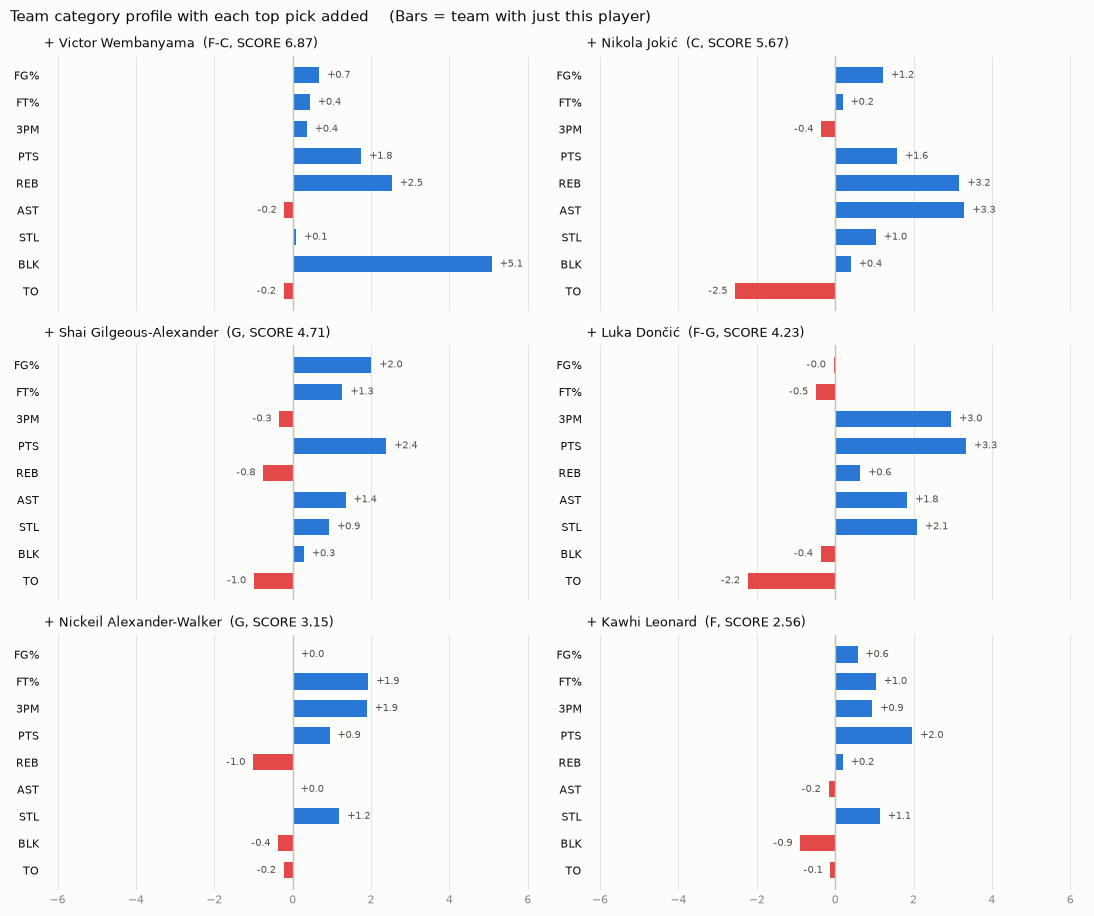

In [14]:
best_available(weights={'TO': 0.2, 'STL': 0.2, '3PM': -0.4})


## My team

Sum of z-scores per category. Positive = you're ahead of an average team in that category; the weakest categories are what to target (or punt).

In [15]:
def my_team():
    if not mine:
        print("No players in MINE yet.")
        return
    team = rankings[rankings["PLAYER_NAME"].isin(mine)]
    display(show(team))
    totals = team[CATS].sum().sort_values()
    print("Category totals, weakest first:")
    print(totals.round(2).to_string())


my_team()

No players in MINE yet.
